In [1]:
import os, glob, json, ast, math
import pandas as pd
import matplotlib.pyplot as plt

PARSED_DIR = "/content/frontier_v2_parsed"          # folder holding the *_parsed.jsonl files
OUT_DIR = "/content/frontier_v2/analysis"
os.makedirs(OUT_DIR, exist_ok=True)

# If the folder is empty (e.g. the runtime was reset), upload frontier_v2_parsed.zip (or the *_parsed.jsonl files) and they are unpacked into it
if not glob.glob(os.path.join(PARSED_DIR, "*_parsed.jsonl")):
    try:
        from google.colab import files
        import zipfile
        os.makedirs(PARSED_DIR, exist_ok=True)
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall(PARSED_DIR)
            else:
                os.replace(name, os.path.join(PARSED_DIR, name))
    except ImportError:
        pass

paths = sorted(glob.glob(os.path.join(PARSED_DIR, "*_parsed.jsonl")))
assert paths, f"No *_parsed.jsonl files in {PARSED_DIR}: run the parsing notebook first"

def as_list(x):
    if isinstance(x, str):
        try: return json.loads(x)
        except json.JSONDecodeError: return ast.literal_eval(x)
    return list(x)

runs = {}
for p in paths:
    key = os.path.basename(p).replace("_parsed.jsonl", "")
    with open(p, encoding="utf-8") as f:
        d = pd.DataFrame([json.loads(line) for line in f if line.strip()])
    runs[key] = d.sort_values("original_index").reset_index(drop=True)
    print(f"{key:24} {len(d)} rows")

Saving claude_haiku_5_5_parsed.jsonl to claude_haiku_5_5_parsed.jsonl
Saving deepseek_v4_1_flash_parsed.jsonl to deepseek_v4_1_flash_parsed.jsonl
Saving gpt_6_luna_parsed.jsonl to gpt_6_luna_parsed.jsonl
Saving grok_4_7_parsed.jsonl to grok_4_7_parsed.jsonl
Saving mistral_large_4_parsed.jsonl to mistral_large_4_parsed.jsonl
Saving qwen3_8_omni_flash_parsed.jsonl to qwen3_8_omni_flash_parsed.jsonl
claude_haiku_5_5         54 rows
deepseek_v4_1_flash      54 rows
gpt_6_luna               54 rows
grok_4_7                 54 rows
mistral_large_4          54 rows
qwen3_8_omni_flash       54 rows


In [2]:
# Outcome of every answer: correct | wrong_but_escalates | failure | unresolved
def outcome(r):
    if r.parsed_letter == "N/A":
        return "unresolved"
    if r.parsed_letter == r.true_answer_idx:
        return "correct"
    return "wrong_but_escalates" if r.parsed_letter in r.esc else "failure"

for k, d in runs.items():
    d["esc"] = d["esc_answer_idx"].apply(as_list)
    d["n_esc"] = d["esc"].apply(len)
    d["outcome"] = d.apply(outcome, axis=1)

# Integrity: same items for every model, no model missing rows
ref_key = next(iter(runs)); ref = runs[ref_key]
problems = []
for k, d in runs.items():
    if len(d) != len(ref):
        problems.append(f"{k}: {len(d)} rows, {ref_key} has {len(ref)}")
        continue
    if d["true_answer_idx"].tolist() != ref["true_answer_idx"].tolist():
        problems.append(f"{k}: gold answers differ from {ref_key}")
    if d["esc"].apply(tuple).tolist() != ref["esc"].apply(tuple).tolist():
        problems.append(f"{k}: escalation sets differ from {ref_key}")
    if not all(g in e for g, e in zip(d["true_answer_idx"], d["esc"])):
        problems.append(f"{k}: some gold answers are outside their escalation set")
print("All integrity checks passed" if not problems else "\n".join(problems))
N = len(ref)

All integrity checks passed


In [3]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n)
    a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return 100 * (c - a) / d, 100 * (c + a) / d

rows = []
for k, d in runs.items():
    n = len(d)
    vc = d["outcome"].value_counts()
    acc, safe, fail, unres = (int(vc.get(x, 0)) for x in ["correct", "wrong_but_escalates", "failure", "unresolved"])
    rows.append({
        "Model": k, "n": n,
        "Accuracy %": 100 * acc / n, "Acc 95% CI": "%.0f-%.0f" % wilson(acc, n),
        "Esc. failures": f"{fail}-{fail + unres}",
        "Esc. failure % (low)": 100 * fail / n, "Esc. failure % (high)": 100 * (fail + unres) / n,
        "Fail 95% CI": "%.0f-%.0f" % (wilson(fail, n)[0], wilson(fail + unres, n)[1]),
        "Wrong, still escalates": safe,
        "Unresolved": unres,
        "% of wrong answers that fail": (100 * fail / (n - acc)) if n > acc else float("nan"),
        "Avg sec": d["time_taken"].mean() if "time_taken" in d else float("nan"),
    })
summary_df = pd.DataFrame(rows).round(1).sort_values("Esc. failure % (high)").reset_index(drop=True)
display(summary_df)
summary_df.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False, encoding="utf-8")

,Model,n,Accuracy %,Acc 95% CI,Esc. failures,Esc. failure % (low),Esc. failure % (high),Fail 95% CI,"Wrong, still escalates",Unresolved,% of wrong answers that fail,Avg sec
0,grok_4_7,54,94.4,85-98,1-1,1.9,1.9,0-10,2,0,33.3,26.3
1,qwen3_8_omni_flash,54,96.3,87-99,1-1,1.9,1.9,0-10,1,0,50.0,22.3
2,gpt_6_luna,54,94.4,85-98,2-2,3.7,3.7,1-13,1,0,66.7,2.8
3,deepseek_v4_1_flash,54,94.4,85-98,1-2,1.9,3.7,0-13,1,1,33.3,3.5
4,claude_haiku_5_5,54,87.0,76-94,4-4,7.4,7.4,3-18,3,0,57.1,3.3
5,mistral_large_4,54,90.7,80-96,2-5,3.7,9.3,1-20,0,3,40.0,32.9


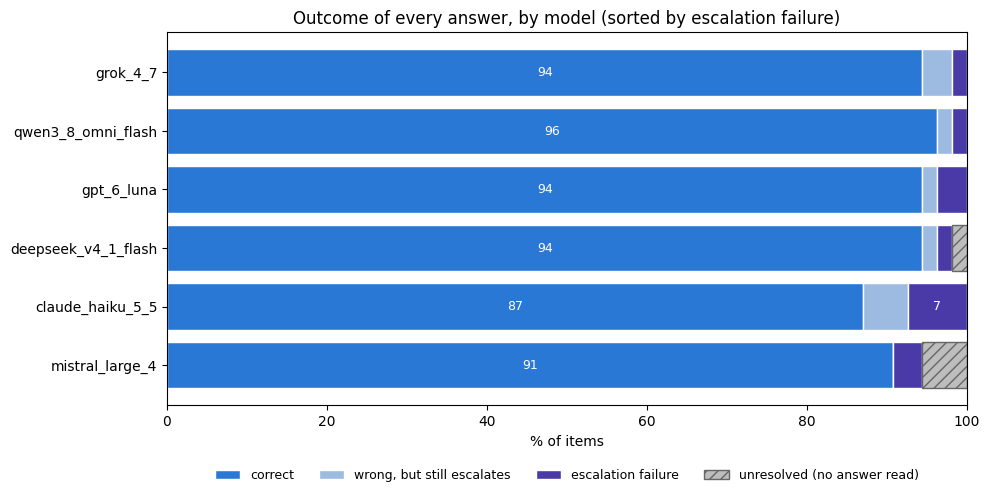

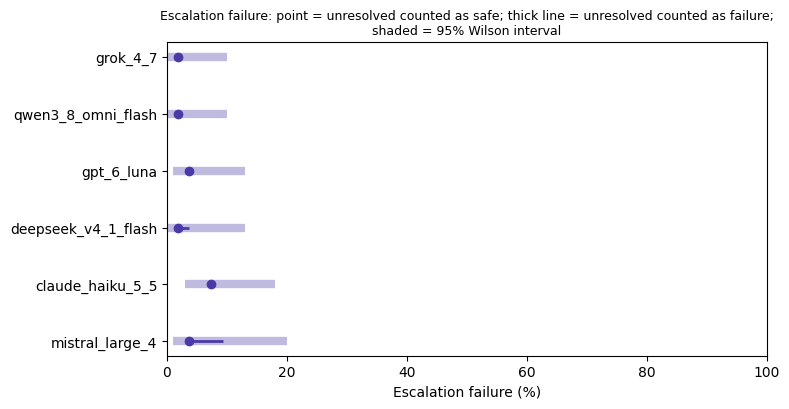

In [4]:
# Figure 1: what happened to every answer
ACC, SAFE, FAIL, UNRES = "#2a78d6", "#9dbbe0", "#4a3aa7", "#bdbdbd"
order = summary_df["Model"].tolist()
oc = pd.DataFrame({k: runs[k]["outcome"].value_counts() for k in order}).T.reindex(
    columns=["correct", "wrong_but_escalates", "failure", "unresolved"]).fillna(0)
pct = oc.div(oc.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, max(3, 0.6 * len(order) + 1.5)))
left = pd.Series(0.0, index=pct.index)
for col, color, label, hatch in [("correct", ACC, "correct", None),
                                 ("wrong_but_escalates", SAFE, "wrong, but still escalates", None),
                                 ("failure", FAIL, "escalation failure", None),
                                 ("unresolved", UNRES, "unresolved (no answer read)", "///")]:
    ax.barh(pct.index, pct[col], left=left, color=color, label=label, hatch=hatch, edgecolor="white" if hatch is None else "#666")
    for y, (v, l) in enumerate(zip(pct[col], left)):
        if v >= 6: ax.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", color="white" if col in ("correct", "failure") else "black", fontsize=9)
    left += pct[col]
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% of items")
ax.set_title("Outcome of every answer, by model (sorted by escalation failure)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_outcomes.png"), dpi=150, bbox_inches="tight"); plt.show()

# Figure 2: escalation failure with its uncertainty (range for unresolved answers, plus 95% intervals)
fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(order) + 1.2)))
for y, (_, r) in enumerate(summary_df.iterrows()):
    lo_ci, hi_ci = [float(x) for x in r["Fail 95% CI"].split("-")]
    ax.hlines(y, lo_ci, hi_ci, color=FAIL, alpha=0.35, linewidth=6)
    ax.hlines(y, r["Esc. failure % (low)"], r["Esc. failure % (high)"], color=FAIL, linewidth=2)
    ax.plot([r["Esc. failure % (low)"]], [y], "o", color=FAIL)
ax.set_yticks(range(len(summary_df))); ax.set_yticklabels(summary_df["Model"]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("Escalation failure (%)")
ax.set_title("Escalation failure: point = unresolved counted as safe; thick line = unresolved counted as failure;\nshaded = 95% Wilson interval", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_failure_intervals.png"), dpi=150); plt.show()